In [3]:
!pip install skorch -q

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [6]:
#vérification du chemin des fichiers
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv
/kaggle/input/datasets/dgawlik/nyse/fundamentals.csv
/kaggle/input/datasets/dgawlik/nyse/prices.csv
/kaggle/input/datasets/dgawlik/nyse/securities.csv


(851264, 7)
        date symbol        open       close         low        high     volume
0 2016-01-05   WLTW  123.430000  125.839996  122.309998  126.250000  2163600.0
1 2016-01-06   WLTW  125.239998  119.980003  119.940002  125.540001  2386400.0
2 2016-01-07   WLTW  116.379997  114.949997  114.930000  119.739998  2489500.0
3 2016-01-08   WLTW  115.480003  116.620003  113.500000  117.440002  2006300.0
4 2016-01-11   WLTW  117.010002  114.970001  114.089996  117.330002  1408600.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       

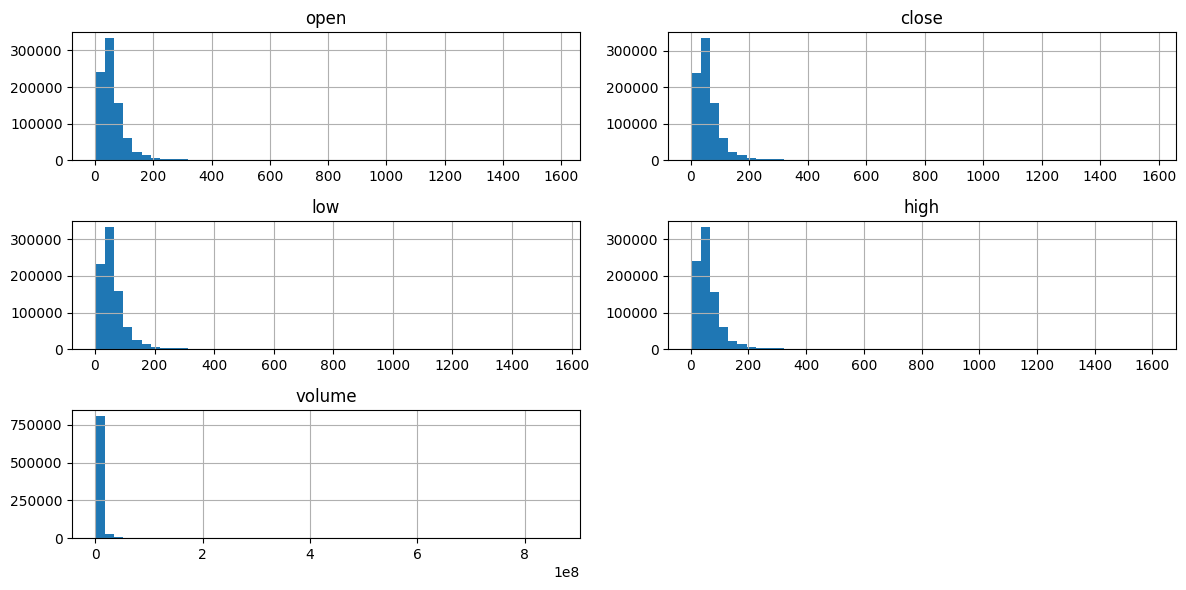

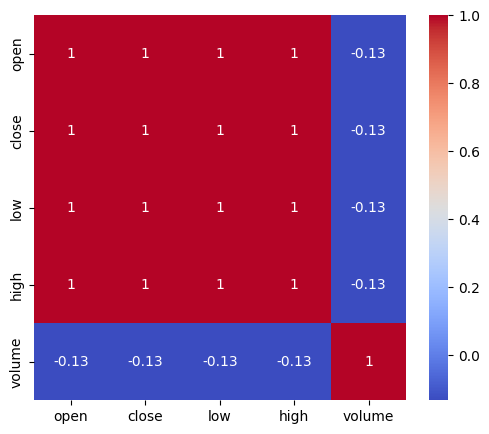

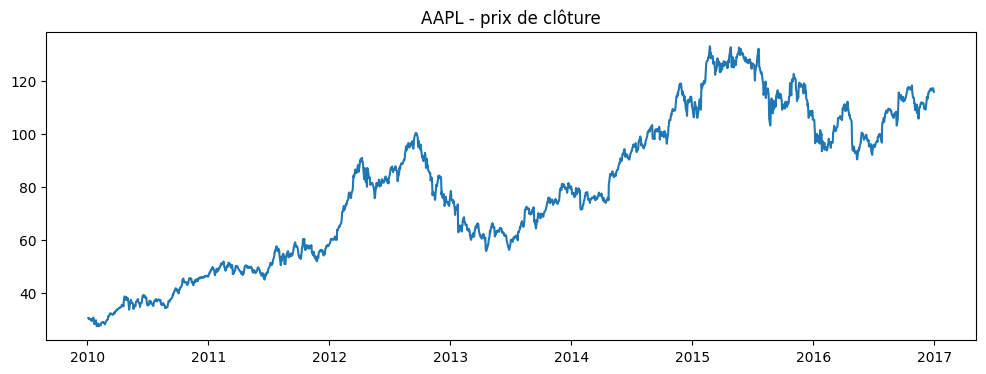

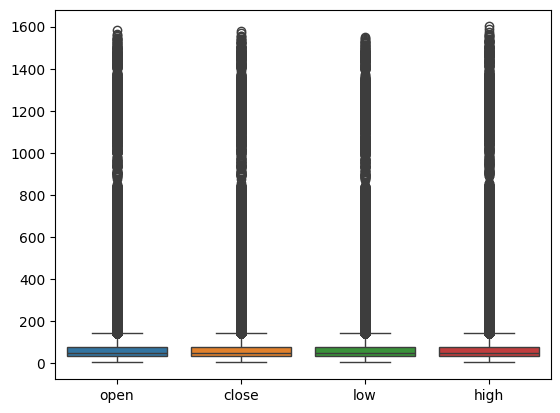

In [8]:
df = pd.read_csv("/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv", parse_dates=["date"])

print(df.shape)
print(df.head())
df.info()
print(df.describe())
print("Valeurs manquantes :\n", df.isnull().sum())
print("Nombre de sociétés :", df["symbol"].nunique())

# Distributions
df[["open","close","low","high","volume"]].hist(bins=50, figsize=(12,6))
plt.tight_layout(); plt.show()

# Corrélations
plt.figure(figsize=(6,5))
sns.heatmap(df[["open","close","low","high","volume"]].corr(), annot=True, cmap="coolwarm")
plt.show()

# Évolution d'une action
aapl = df[df["symbol"]=="AAPL"]
plt.figure(figsize=(12,4))
plt.plot(aapl["date"], aapl["close"])
plt.title("AAPL - prix de clôture"); plt.show()

# Outliers
sns.boxplot(data=df[["open","close","low","high"]]); plt.show()